In [43]:
from pipelinespec.cli.diff import METRICS, compare
from pipelinespec.models import Constraints
from itertools import combinations
from pydantic import TypeAdapter
from statistics import mean
from pathlib import Path
import pandas as pd

RESULTS = Path('../data/results')

adapter = TypeAdapter(dict[str, Constraints])
outputs = {}

for model in sorted(path for path in RESULTS.iterdir() if path.is_dir()):
    for repo in sorted(path for path in model.iterdir() if path.is_dir()):
        files = sorted(repo.glob('constraints*.json'))

        if files:
            outputs[model.name, repo.name] = [adapter.validate_json(path.read_text()) for path in files]

models = sorted({model for model, _ in outputs})
repos = sorted({repo for _, repo in outputs})

In [44]:
comparisons = [(f'{model} (k={len(files)})', repo, files) for (model, repo), files in outputs.items() if len(files) > 1]
comparisons += [(f'{left} vs {right}', repo, [outputs[left, repo][0], outputs[right, repo][0]]) for left, right in combinations(models, 2) for repo in repos if (left, repo) in outputs and (right, repo) in outputs]

rows = []
undecided = []

for comparison, repo, files in comparisons:
    scores, _, empty, unknown = compare(files)
    rows += [{'comparison': comparison, 'repo': repo, 'job': job, 'empty': job in empty, 'metric': metric, 'score': mean(values)} for job, row in scores.items() for metric, values in row.items() if values]
    undecided += [{'comparison': comparison, 'repo': repo, 'gate': gate} for gate in sorted(unknown)]

scores = pd.DataFrame(rows)
undecided = pd.DataFrame(undecided, columns=['comparison', 'repo', 'gate'])
undecided

,comparison,repo,gate
0,gpt-6-luna (k=3),excalidraw,Semantic PR title / label-scope @ .github/work...
1,gpt-6-luna (k=3),langchain,🏷️ PR Title Lint / lint-pr-title @ .github/wor...
2,gpt-6-luna (k=3),langchain,🏷️ PR trailer lint / trailer-check @ .github/w...
3,gpt-6-luna (k=3),tensorflow,Reusable Build / build-and-test @ ci/official/...
4,gpt-6-luna (k=3),tensorflow,Reusable Build / build-and-test @ ci/official/...
5,claude-haiku-5-5 vs gpt-6-luna,spec-kit,Catalog: Notify submission / notify @ .github/...


In [45]:
recorded = scores[~scores['empty'] | (scores['metric'] == 'events')].assign(agree=lambda frame: frame.score == 1)

display(recorded.pivot_table(index='comparison', columns='metric', values='score', aggfunc='mean').reindex(columns=list(METRICS)).round(3))
display(recorded.pivot_table(index='comparison', columns='metric', values='agree', aggfunc='mean').reindex(columns=list(METRICS)).round(3))

metric,events,gate locations,equivalent gates,unsolved,variables,constants
comparison,,,,,,
claude-haiku-5-5 vs gpt-6-luna,1.0,0.732,0.707,0.479,0.783,0.724
gpt-6-luna (k=3),1.0,0.850,0.772,0.572,0.898,0.806


metric,events,gate locations,equivalent gates,unsolved,variables,constants
comparison,,,,,,
claude-haiku-5-5 vs gpt-6-luna,1.000,0.647,0.630,0.298,0.697,0.682
gpt-6-luna (k=3),0.999,0.715,0.616,0.280,0.778,0.686


In [46]:
mean_scores = recorded.pivot_table(index='comparison', columns='metric', values='score', aggfunc='mean').reindex(columns=list(METRICS))
agreement = recorded.pivot_table(index='comparison', columns='metric', values='agree', aggfunc='mean').reindex(columns=list(METRICS))

covered = recorded.drop_duplicates(['comparison', 'repo', 'job'])
covers = pd.DataFrame({'repositories': covered.groupby('comparison')['repo'].nunique(), 'jobs': covered.groupby('comparison').size(), 'jobs with constraints': covered[~covered['empty']].groupby('comparison').size()})

display(pd.concat({'mean score': mean_scores, 'exact agreement': agreement}, axis=1).round(2))
display(covers)

mean score                                  \
metric                             events gate locations equivalent gates   
comparison                                                                  
claude-haiku-5-5 vs gpt-6-luna        1.0           0.73             0.71   
gpt-6-luna (k=3)                      1.0           0.85             0.77   

                                                            exact agreement  \
metric                         unsolved variables constants          events   
comparison                                                                    
claude-haiku-5-5 vs gpt-6-luna     0.48      0.78      0.72             1.0   
gpt-6-luna (k=3)                   0.57      0.90      0.81             1.0   

                                                                         \
metric                         gate locations equivalent gates unsolved   
comparison                                                                
claude-haiku-5-5 vs gpt-6-luna           0.65             0.63     0.30   
gpt-6-luna (k=3)                         0.71             0.62     0.28   

                                                    
metric                         variables constants  
comparison                                          
claude-haiku-5-5 vs gpt-6-luna      0.70      0.68  
gpt-6-luna (k=3)                    0.78      0.69

,repositories,jobs,jobs with constraints
comparison,,,
claude-haiku-5-5 vs gpt-6-luna,30,925,815
gpt-6-luna (k=3),30,925,835


analysis/claude-haiku-5-5 vs gpt-6-luna.pdf


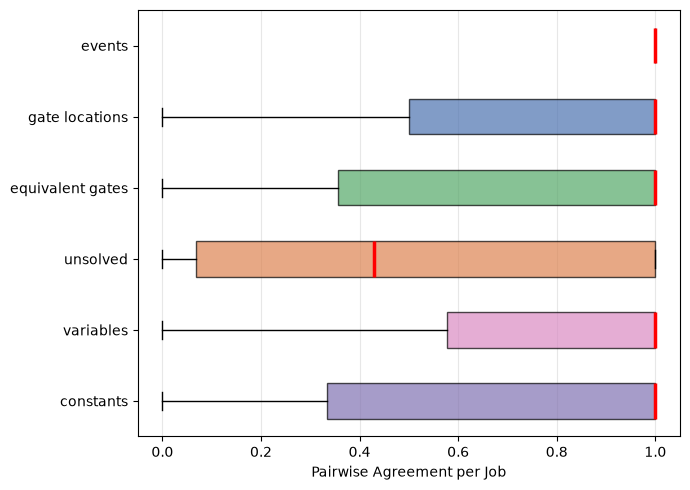

analysis/gpt-6-luna (k=3).pdf


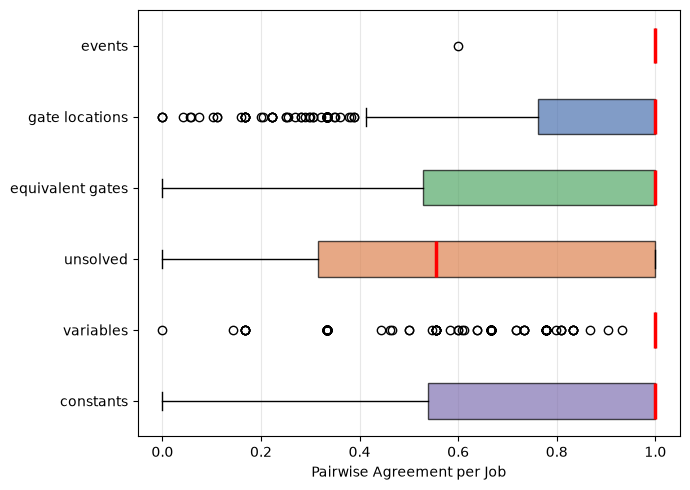

In [47]:
import matplotlib.pyplot as plt

colors = ['#4C72B0', '#DD8452', '#55A868', '#8172B2', '#C44E52']
COLORS = {
    'events': colors[4],
    'gate locations': colors[0],
    'equivalent gates': colors[2],
    'unsolved': colors[1],
    'variables': '#DA8BC3',
    'constants': colors[3],
}

metrics = list(METRICS)

for name in sorted(recorded['comparison'].unique()):
    chosen = recorded[recorded['comparison'] == name]

    fig, ax = plt.subplots(figsize=(7, 5))
    plot = ax.boxplot([chosen[chosen['metric'] == metric]['score'] for metric in metrics], orientation='horizontal', patch_artist=True, medianprops={'color': 'red', 'linewidth': 2.5})

    for box, metric in zip(plot['boxes'], metrics):
        box.set_facecolor(COLORS[metric])
        box.set_alpha(0.7)

    ax.set_yticks(range(1, len(metrics) + 1), labels=metrics)
    ax.invert_yaxis()
    ax.set_xlabel('Pairwise Agreement per Job')
    ax.set_xlim(-0.05, 1.05)
    ax.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    print(f'analysis/{name}.pdf')
    plt.savefig(f'{name}.pdf', bbox_inches='tight')
    plt.show()

In [48]:
luna, haiku = 'gpt-6-luna (k=3)', 'claude-haiku-5-5 vs gpt-6-luna'

quartiles = recorded.groupby(['comparison', 'metric'])['score'].quantile([0.25, 0.75]).unstack()
quartiles.columns = ['q1', 'q3']
quartiles['iqr'] = quartiles['q3'] - quartiles['q1']

iqr = quartiles['iqr'].unstack('metric').reindex(columns=list(METRICS))
lower = quartiles['q1'].unstack('metric').reindex(columns=list(METRICS))

display(pd.concat({'IQR': iqr, 'lower quartile': lower}, axis=1).round(2))
display(pd.DataFrame({'IQR increase': iqr.loc[haiku] - iqr.loc[luna], 'lower quartile drop': lower.loc[luna] - lower.loc[haiku]}).round(2))

IQR                                  \
metric                         events gate locations equivalent gates   
comparison                                                              
claude-haiku-5-5 vs gpt-6-luna    0.0           0.50             0.64   
gpt-6-luna (k=3)                  0.0           0.24             0.47   

                                                            lower quartile  \
metric                         unsolved variables constants         events   
comparison                                                                   
claude-haiku-5-5 vs gpt-6-luna     0.93      0.42      0.67            1.0   
gpt-6-luna (k=3)                   0.69      0.00      0.46            1.0   

                                                                         \
metric                         gate locations equivalent gates unsolved   
comparison                                                                
claude-haiku-5-5 vs gpt-6-luna           0.50             0.36     0.07   
gpt-6-luna (k=3)                         0.76             0.53     0.31   

                                                    
metric                         variables constants  
comparison                                          
claude-haiku-5-5 vs gpt-6-luna      0.58      0.33  
gpt-6-luna (k=3)                    1.00      0.54

,IQR increase,lower quartile drop
metric,,
events,0.00,0.00
gate locations,0.26,0.26
equivalent gates,0.17,0.17
unsolved,0.25,0.25
variables,0.42,0.42
constants,0.21,0.21
